<div style="display:flex; align-items:center; justify-content:space-between; border-bottom:1px solid #d9d9d9; padding-bottom:12px;">
  <div style=
    "width:22%;">
    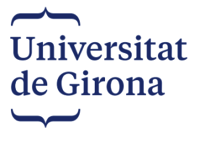
  </div>
  <div style="width:78%; text-align:right;">
    <div style="font-size:20px; font-weight:700;">Machine Learning</div>
    <div style="font-size:26px; font-weight:700; margin-top:4px;">Lab 1: Gradient Descent for Laptop Price Prediction</div>
  </div>
</div>

<br>

<table style="width:100%; border-collapse:collapse; font-size:15px;">
<tr>
<td style="padding:5px 0;"><b>Student University Number:</b>u6120321</td>
</tr>
<tr>
<td style="padding:5px 0;"><b>First Name:</b> Md. Rimon &nbsp;&nbsp;&nbsp;&nbsp; <b>Family Name:</b> Miah</td>
</tr>
</table>

> ### Before You Begin
>
> Click **Copy to Drive** at the top of this notebook.
>
> This will create your own editable copy in your Google Drive.  
> Complete all exercises and save your work in your own copy.
>
> **Do not work directly on the original notebook, since your changes may not be saved.**

## Goals

By the end of this lab, you should be able to:

- explain what the parameters of a linear regression model control,
- understand what the cost function measures,
- see how gradient descent changes the model parameters,
- explain what the gradient represents,
- understand how the learning rate affects convergence,
- explain why this implementation is called batch gradient descent,
- use learned parameters to make a prediction.

In [3]:
!python3 -m pip install gdown


   ---------------------------------------- 0/4 [tqdm]
   ---------- ----------------------------- 1/4 [PySocks]
   -------------------- ------------------- 2/4 [filelock]
   ---------------------------------------- 4/4 [gdown]



# Problem Statement

Laptop prices depend on the hardware inside the computer.

In this lab, we use a **GPU performance score** to predict laptop price.

The linear model is

$$
h(x) = \theta_0 + \theta_1 x
$$

where:

- $x$ is the GPU performance score
- $\theta_0$ is the intercept
- $\theta_1$ is the slope
- $h(x)$ is the predicted laptop price

We will use **gradient descent** to change $\theta_0$ and $\theta_1$ step by step until the prediction error becomes smaller.

# 1. Setup

The dataset is stored in Google Drive.

Mount Google Drive and load `laptop_regression_lab.csv`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from pathlib import Path

## 1.1 Load the dataset

In [9]:
import gdown

FILE_URL = "https://drive.google.com/file/d/1HQ8HWXlmHoD2zVg_Ajl2vLwGXMF40Ngj/view?usp=sharing"

DATA_PATH = Path("regression_lab.csv")

gdown.download(
    FILE_URL,
    str(DATA_PATH),
    quiet=False
)

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

df.head()

Downloading...
From: https://drive.google.com/uc?id=1HQ8HWXlmHoD2zVg_Ajl2vLwGXMF40Ngj
To: D:\IFRoS Course Material\1.1\Machine Learning\Lab1\regression_lab.csv
100%|██████████| 3.62k/3.62k [00:00<00:00, 6.03MB/s]


Dataset loaded successfully.
Dataset shape: (70, 11)


,laptop_id,cpu_score,gpu_score,ram_gb,ssd_gb,display_score,build_quality_score,refresh_rate_hz,touchscreen,price_eur,split
0,L001,87.5,85.2,48,1024,82.9,75.0,165,0,2710,train
1,L002,42.7,21.8,8,256,48.6,45.0,60,0,1170,train
2,L003,56.1,38.9,16,512,67.9,47.2,90,0,1500,train
3,L004,84.6,84.1,32,1024,97.0,84.9,165,1,2730,validation
4,L005,57.7,54.7,32,512,65.7,69.5,120,1,2000,train


## 1.2 Prepare the training data

In [10]:
train_df = df[df["split"] == "train"].copy()

gpu_score_values = train_df["gpu_score"].to_numpy(dtype=float)
y = train_df["price_eur"].to_numpy(dtype=float)

# Divide GPU score by 10 for the gradient-descent calculations.
# Example: GPU score 70 becomes x = 7.0.
x = gpu_score_values / 10.0

m = len(x)

print("Number of training laptops:", m)
print(
    "GPU score range:",
    gpu_score_values.min(),
    "to",
    gpu_score_values.max(),
)
print(
    "Laptop price range:",
    y.min(),
    "to",
    y.max(),
    "EUR",
)

Number of training laptops: 56
GPU score range: 10.8 to 93.9
Laptop price range: 1020.0 to 3420.0 EUR


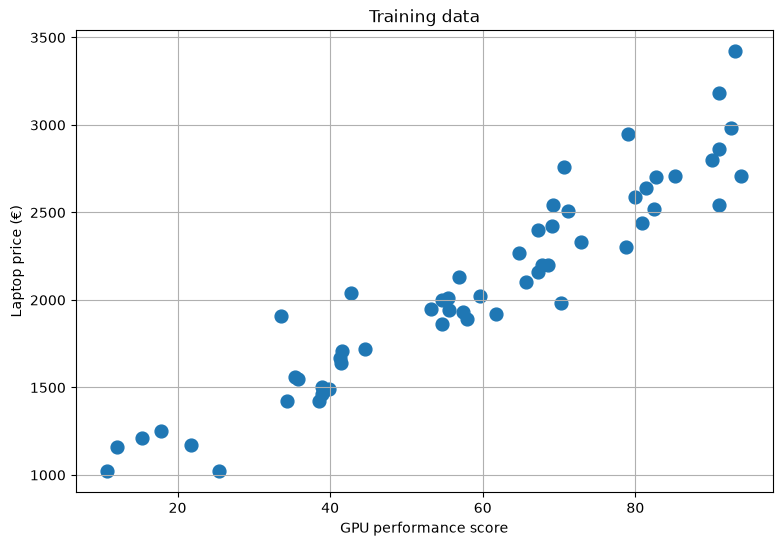

In [11]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    gpu_score_values,
    y,
    s=85,
)

ax.set_xlabel("GPU performance score")
ax.set_ylabel("Laptop price (€)")
ax.set_title("Training data")
ax.grid(True)

plt.show()

# 2. Play with the Model Parameters

Before running gradient descent, first see what the two parameters do.

$$
h(x) = \theta_0 + \theta_1 x
$$

Change only `theta0_play` and `theta1_play`, then run the cell again.

In this experiment, $x$ is the GPU score divided by 10.

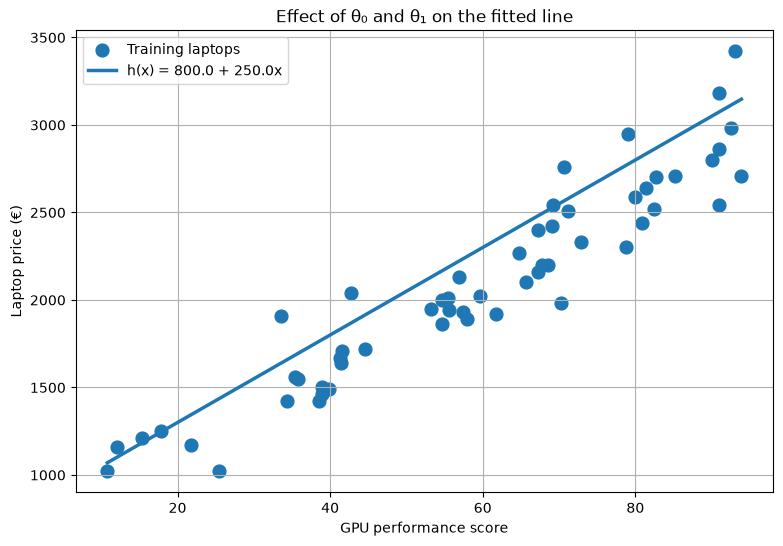

In [15]:
# ==================================================
# PLAY WITH THESE TWO VALUES
# ==================================================
theta0_play = 800.0
theta1_play = 250.0
# ==================================================

gpu_line = np.linspace(
    gpu_score_values.min(),
    gpu_score_values.max(),
    300,
)

x_line = gpu_line / 10.0
y_line = theta0_play + theta1_play * x_line

fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    gpu_score_values,
    y,
    s=85,
    label="Training laptops",
)

ax.plot(
    gpu_line,
    y_line,
    linewidth=2.5,
    label=f"h(x) = {theta0_play:.1f} + {theta1_play:.1f}x",
)

ax.set_xlabel("GPU performance score")
ax.set_ylabel("Laptop price (€)")
ax.set_title("Effect of θ₀ and θ₁ on the fitted line")
ax.grid(True)
ax.legend()

plt.show()

<div style="border-left:5px solid #b00020; padding:10px 14px; margin:14px 0;">
<div style="color:#b00020; font-weight:700;">Question</div>
<div style="margin-top:6px;"><b>Increase θ₁ and rerun the parameter-playground cell. What changes in the line? Then change θ₀. What does each parameter control?</b></div>

<div style="color:#b00020; margin-top:8px;">
<b>Your answer:</b><br><br>
Changing Theta1 control the slop the line and theta0 control the parallel distance from x axis.
<br><br>
................................................................................................................................................
</div>

</div>

# 3. Cost Function

We need a number that tells us how well the current line fits the training data.

We use the squared-error cost:

$$
J(\theta_0,\theta_1)
=
\frac{1}{2m}
\sum_{i=1}^{m}
\left(h(x^{(i)})-y^{(i)}\right)^2
$$

A smaller cost means the predictions are closer to the observed target values.

In [16]:
def compute_cost(theta0, theta1, x, y):
    predictions = theta0 + theta1 * x
    errors = predictions - y

    cost = np.sum(errors ** 2) / (2 * len(x))

    return cost

J(0.0, 250.0) = 206557.31


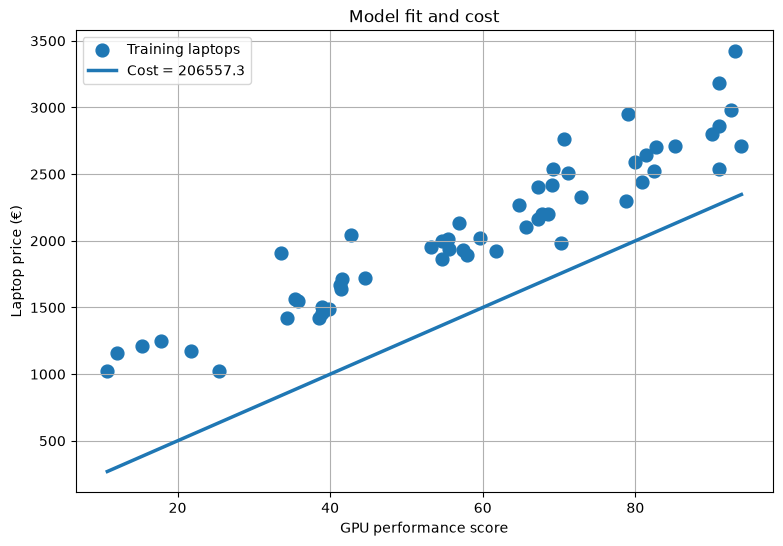

In [18]:
# ==================================================
# PLAY WITH THESE VALUES
# ==================================================
theta0_cost = 800.0
theta1_cost = 250.0
# ==================================================

current_cost = compute_cost(
    theta0_cost,
    theta1_cost,
    x,
    y,
)

print(
    f"J({theta0_cost:.1f}, {theta1_cost:.1f}) "
    f"= {current_cost:.2f}"
)

gpu_line = np.linspace(
    gpu_score_values.min(),
    gpu_score_values.max(),
    300,
)

x_line = gpu_line / 10.0

fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    gpu_score_values,
    y,
    s=85,
    label="Training laptops",
)

ax.plot(
    gpu_line,
    theta0_cost + theta1_cost * x_line,
    linewidth=2.5,
    label=f"Cost = {current_cost:.1f}",
)

ax.set_xlabel("GPU performance score")
ax.set_ylabel("Laptop price (€)")
ax.set_title("Model fit and cost")
ax.grid(True)
ax.legend()

plt.show()

<div style="border-left:5px solid #b00020; padding:10px 14px; margin:14px 0;">
<div style="color:#b00020; font-weight:700;">Question</div>
<div style="margin-top:6px;"><b>Try different pairs of θ₀ and θ₁. When the fitted line moves closer to the training observations, what happens to the cost J?</b></div>

<div style="color:#b00020; margin-top:8px;">
<b>Your answer:</b><br><br>
if we increase theta0, J decrease.
</div>

</div>

## 3.1 The Cost Surface

Every pair of parameter values $(\theta_0,\theta_1)$ has a cost.

The contour plot below shows the cost for many parameter combinations.

The lowest region corresponds to parameter values that fit the training data best.

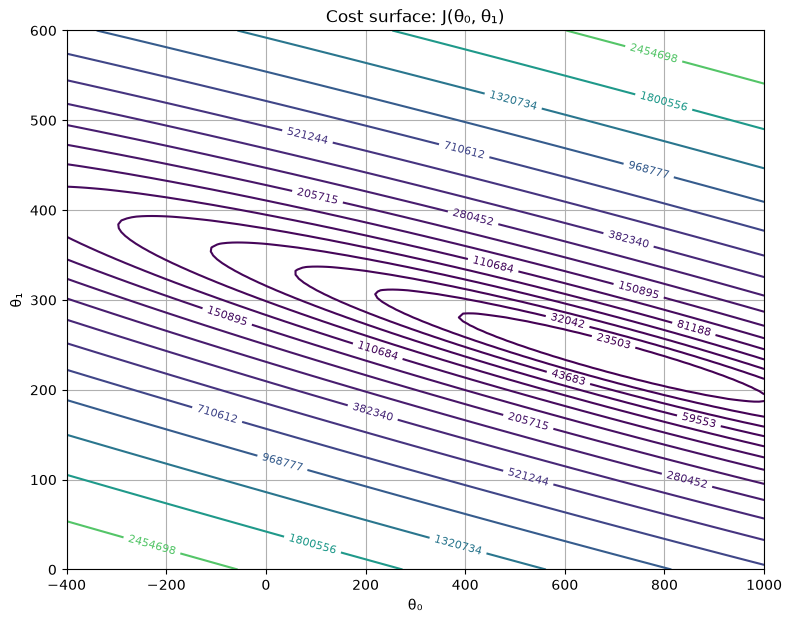

In [19]:
theta0_values = np.linspace(-400, 1000, 140)
theta1_values = np.linspace(0, 600, 140)

T0, T1 = np.meshgrid(
    theta0_values,
    theta1_values,
)

J = np.zeros_like(T0)

for row in range(T0.shape[0]):
    for col in range(T0.shape[1]):
        J[row, col] = compute_cost(
            T0[row, col],
            T1[row, col],
            x,
            y,
        )

fig, ax = plt.subplots(figsize=(9, 7))

levels = np.geomspace(
    max(J.min(), 1),
    J.max(),
    18,
)

contours = ax.contour(
    T0,
    T1,
    J,
    levels=levels,
)

ax.clabel(
    contours,
    inline=True,
    fontsize=8,
)

ax.set_xlabel("θ₀")
ax.set_ylabel("θ₁")
ax.set_title("Cost surface: J(θ₀, θ₁)")
ax.grid(True)

plt.show()

# 4. One Gradient Descent Step

Gradient descent changes the parameters in the direction that reduces the cost.

$$
\theta_0 := \theta_0 - \alpha \frac{\partial J}{\partial \theta_0}
$$

$$
\theta_1 := \theta_1 - \alpha \frac{\partial J}{\partial \theta_1}
$$

The derivatives form the **gradient**.

The learning rate $\alpha$ controls the size of each update.

In [20]:
theta0 = 0.0
theta1 = 0.0

alpha = 0.05

predictions = theta0 + theta1 * x
errors = predictions - y

# The gradients use all training observations.
gradient_theta0 = np.mean(errors)
gradient_theta1 = np.mean(errors * x)

new_theta0 = theta0 - alpha * gradient_theta0
new_theta1 = theta1 - alpha * gradient_theta1

print("Before the update")
print("θ₀ =", theta0)
print("θ₁ =", theta1)

print("\nGradient")
print("∂J/∂θ₀ =", round(gradient_theta0, 3))
print("∂J/∂θ₁ =", round(gradient_theta1, 3))

print("\nAfter one gradient-descent update")
print("θ₀ =", round(new_theta0, 3))
print("θ₁ =", round(new_theta1, 3))

Before the update
θ₀ = 0.0
θ₁ = 0.0

Gradient
∂J/∂θ₀ = -2085.357
∂J/∂θ₁ = -13482.377

After one gradient-descent update
θ₀ = 104.268
θ₁ = 674.119


<div style="border-left:5px solid #b00020; padding:10px 14px; margin:14px 0;">
<div style="color:#b00020; font-weight:700;">Question</div>
<div style="margin-top:6px;"><b>At θ₀ = 0 and θ₁ = 0, both gradients are negative. Look at the update rule. Why do θ₀ and θ₁ increase after the first update? What does the gradient tell us?</b></div>

<div style="color:#b00020; margin-top:8px;">
<b>Your answer:</b><br><br>
Negative gradient means the moving to left (Negative side) increase cost . So we need to move right (increase) to reduce the cost (value of the cost function). This is why θ₀ and θ₁ increase after the first update <br><br>
................................................................................................................................................
</div>

</div>

## 4.1 Batch Gradient Descent

Look at the gradient calculation:

```python
gradient_theta0 = np.mean(errors)
gradient_theta1 = np.mean(errors * x)
```

`errors` contains the prediction errors from all training observations.

Each parameter update therefore uses the full training set. This is called **batch gradient descent**.

In [22]:
def gradient_descent(
    x,
    y,
    theta0_init=0.0,
    theta1_init=0.0,
    learning_rate=0.05,
    iterations=1000,
    divergence_limit=1e20,
):
    theta0 = float(theta0_init)
    theta1 = float(theta1_init)

    theta0_history = [theta0]
    theta1_history = [theta1]
    cost_history = [
        compute_cost(theta0, theta1, x, y)
    ]
    print(x)
    for iteration in range(iterations):
        predictions = theta0 + theta1 * x
        errors = predictions - y

        # Batch gradient:
        # every update uses all training observations.
        gradient_theta0 = np.mean(errors)
        gradient_theta1 = np.mean(errors * x)

        # Simultaneous update.
        new_theta0 = (
            theta0
            - learning_rate * gradient_theta0
        )
        new_theta1 = (
            theta1
            - learning_rate * gradient_theta1
        )

        theta0 = new_theta0
        theta1 = new_theta1

        current_cost = compute_cost(
            theta0,
            theta1,
            x,
            y,
        )

        theta0_history.append(theta0)
        theta1_history.append(theta1)
        cost_history.append(current_cost)

        if (
            not np.isfinite(current_cost)
            or current_cost > divergence_limit
        ):
            print(
                "Gradient descent stopped because "
                "the cost is diverging."
            )
            break

    return {
        "theta0": theta0,
        "theta1": theta1,
        "theta0_history": np.asarray(theta0_history),
        "theta1_history": np.asarray(theta1_history),
        "cost_history": np.asarray(cost_history),
    }

<div style="border-left:5px solid #b00020; padding:10px 14px; margin:14px 0;">
<div style="color:#b00020; font-weight:700;">Question</div>
<div style="margin-top:6px;"><b>Why is this called batch gradient descent? How many training observations are used to calculate one parameter update?</b></div>

<div style="color:#b00020; margin-top:8px;">
<b>Your answer:</b><br><br>
    Why it called Batch Gradient descent: It take all data point training set and calculate cost and update the parameter each time.
    
One training loop all data point is used to update parameter once.

<br><br>
................................................................................................................................................
</div>

</div>

# 5. Run Gradient Descent

All the gradient-descent code is already written.

Change the values in the next cell and observe what happens.

Start with the default settings.

In [23]:
# ==================================================
# PLAY WITH THESE VALUES
# ==================================================
theta0_start = 0.0
theta1_start = 0.0
learning_rate = 0.04
iterations = 1000
# ==================================================

result = gradient_descent(
    x=x,
    y=y,
    theta0_init=theta0_start,
    theta1_init=theta1_start,
    learning_rate=learning_rate,
    iterations=iterations,
)

theta0_learned = result["theta0"]
theta1_learned = result["theta1"]

print("Final θ₀:", round(theta0_learned, 3))
print("Final θ₁:", round(theta1_learned, 3))
print(
    "Final cost:",
    round(result["cost_history"][-1], 3),
)

[8.52 2.18 3.89 5.47 9.09 3.98 6.85 7.02 5.79 3.54 3.85 1.79 6.91 5.55
 6.73 7.12 3.58 8.09 5.74 8.   5.32 3.36 4.46 7.06 5.69 1.08 9.25 7.91
 5.97 9.09 9.01 3.43 5.56 2.54 9.09 1.54 8.27 8.25 6.57 6.17 6.47 4.13
 9.39 1.21 4.14 3.89 8.14 5.46 4.16 6.73 7.88 4.27 6.92 9.3  7.29 6.78]
Final θ₀: 693.566
Final θ₁: 236.476
Final cost: 17234.595


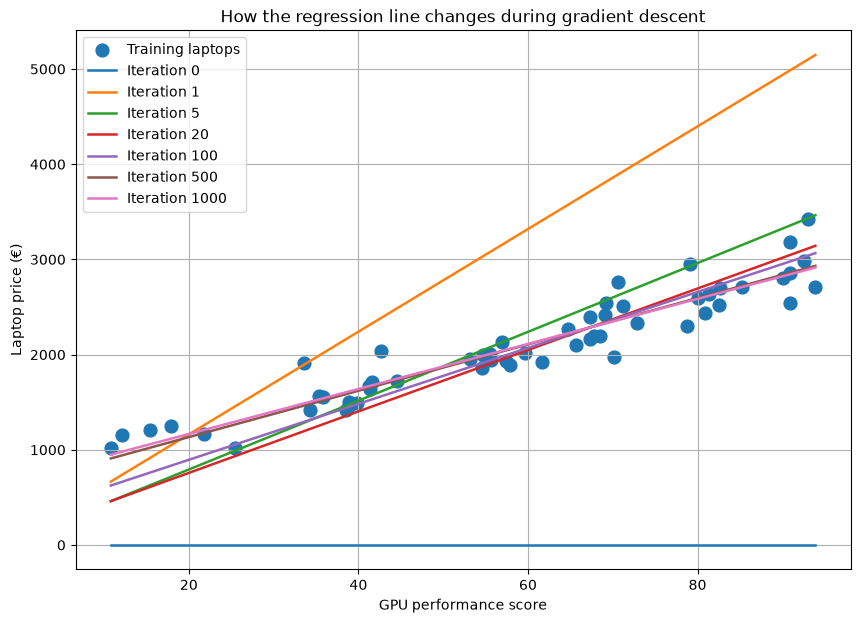

In [24]:
snapshot_iterations = [
    0,
    1,
    5,
    20,
    100,
    min(500, len(result["cost_history"]) - 1),
    len(result["cost_history"]) - 1,
]

snapshot_iterations = list(
    dict.fromkeys(snapshot_iterations)
)

gpu_line = np.linspace(
    gpu_score_values.min(),
    gpu_score_values.max(),
    300,
)

x_line = gpu_line / 10.0

fig, ax = plt.subplots(figsize=(10, 7))

ax.scatter(
    gpu_score_values,
    y,
    s=85,
    label="Training laptops",
)

for step in snapshot_iterations:
    t0 = result["theta0_history"][step]
    t1 = result["theta1_history"][step]

    ax.plot(
        gpu_line,
        t0 + t1 * x_line,
        linewidth=1.8,
        label=f"Iteration {step}",
    )

ax.set_xlabel("GPU performance score")
ax.set_ylabel("Laptop price (€)")
ax.set_title("How the regression line changes during gradient descent")
ax.grid(True)
ax.legend()

plt.show()

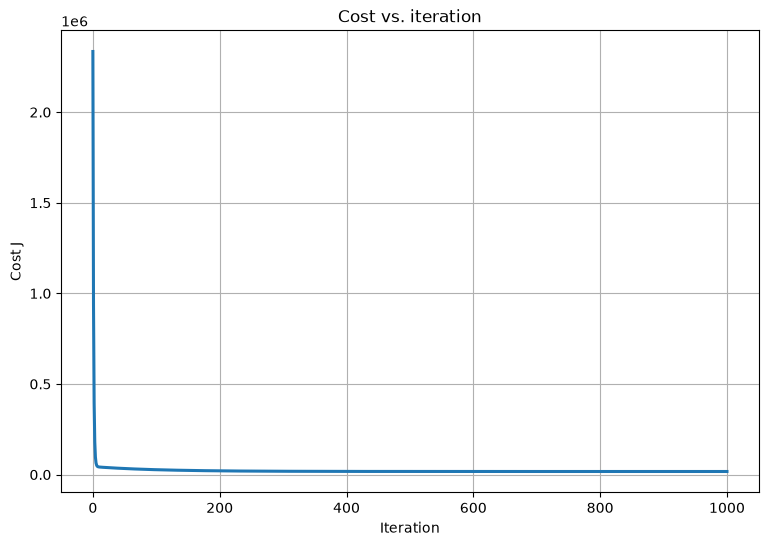

In [26]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(
    result["cost_history"],
    linewidth=2.2,
)

ax.set_xlabel("Iteration")
ax.set_ylabel("Cost J")
ax.set_title("Cost vs. iteration")
ax.grid(True)

plt.show()

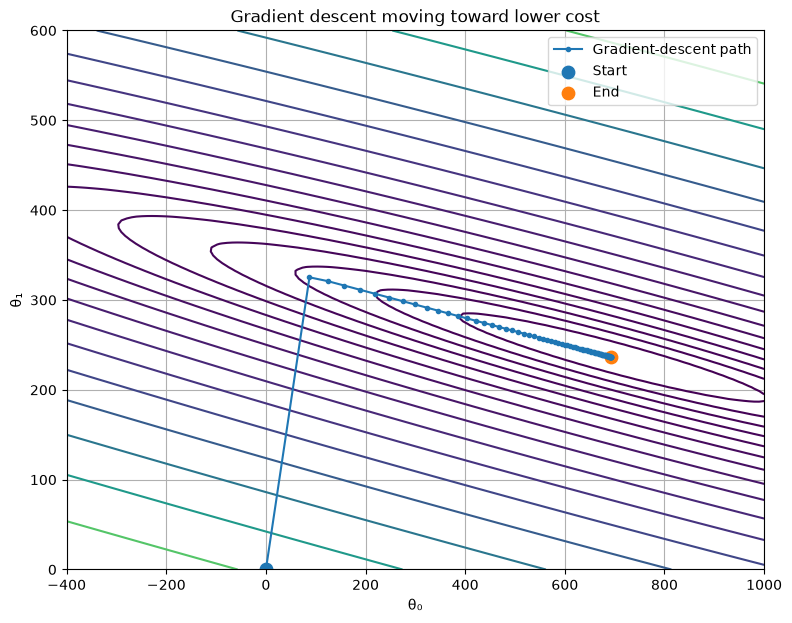

In [27]:
fig, ax = plt.subplots(figsize=(9, 7))

contours = ax.contour(
    T0,
    T1,
    J,
    levels=levels,
)

path_step = max(
    1,
    len(result["theta0_history"]) // 80,
)

ax.plot(
    result["theta0_history"][::path_step],
    result["theta1_history"][::path_step],
    marker="o",
    markersize=3,
    linewidth=1.5,
    label="Gradient-descent path",
)

ax.scatter(
    result["theta0_history"][0],
    result["theta1_history"][0],
    s=80,
    label="Start",
)

ax.scatter(
    result["theta0_history"][-1],
    result["theta1_history"][-1],
    s=80,
    label="End",
)

ax.set_xlabel("θ₀")
ax.set_ylabel("θ₁")
ax.set_title("Gradient descent moving toward lower cost")
ax.grid(True)
ax.legend()

plt.show()

# 6. Learning Rate Experiment

The learning rate controls the size of the gradient-descent step.

Compare:

- a small learning rate,
- a suitable learning rate,
- a learning rate that is too large.

[8.52 2.18 3.89 5.47 9.09 3.98 6.85 7.02 5.79 3.54 3.85 1.79 6.91 5.55
 6.73 7.12 3.58 8.09 5.74 8.   5.32 3.36 4.46 7.06 5.69 1.08 9.25 7.91
 5.97 9.09 9.01 3.43 5.56 2.54 9.09 1.54 8.27 8.25 6.57 6.17 6.47 4.13
 9.39 1.21 4.14 3.89 8.14 5.46 4.16 6.73 7.88 4.27 6.92 9.3  7.29 6.78]
[8.52 2.18 3.89 5.47 9.09 3.98 6.85 7.02 5.79 3.54 3.85 1.79 6.91 5.55
 6.73 7.12 3.58 8.09 5.74 8.   5.32 3.36 4.46 7.06 5.69 1.08 9.25 7.91
 5.97 9.09 9.01 3.43 5.56 2.54 9.09 1.54 8.27 8.25 6.57 6.17 6.47 4.13
 9.39 1.21 4.14 3.89 8.14 5.46 4.16 6.73 7.88 4.27 6.92 9.3  7.29 6.78]
[8.52 2.18 3.89 5.47 9.09 3.98 6.85 7.02 5.79 3.54 3.85 1.79 6.91 5.55
 6.73 7.12 3.58 8.09 5.74 8.   5.32 3.36 4.46 7.06 5.69 1.08 9.25 7.91
 5.97 9.09 9.01 3.43 5.56 2.54 9.09 1.54 8.27 8.25 6.57 6.17 6.47 4.13
 9.39 1.21 4.14 3.89 8.14 5.46 4.16 6.73 7.88 4.27 6.92 9.3  7.29 6.78]
Gradient descent stopped because the cost is diverging.


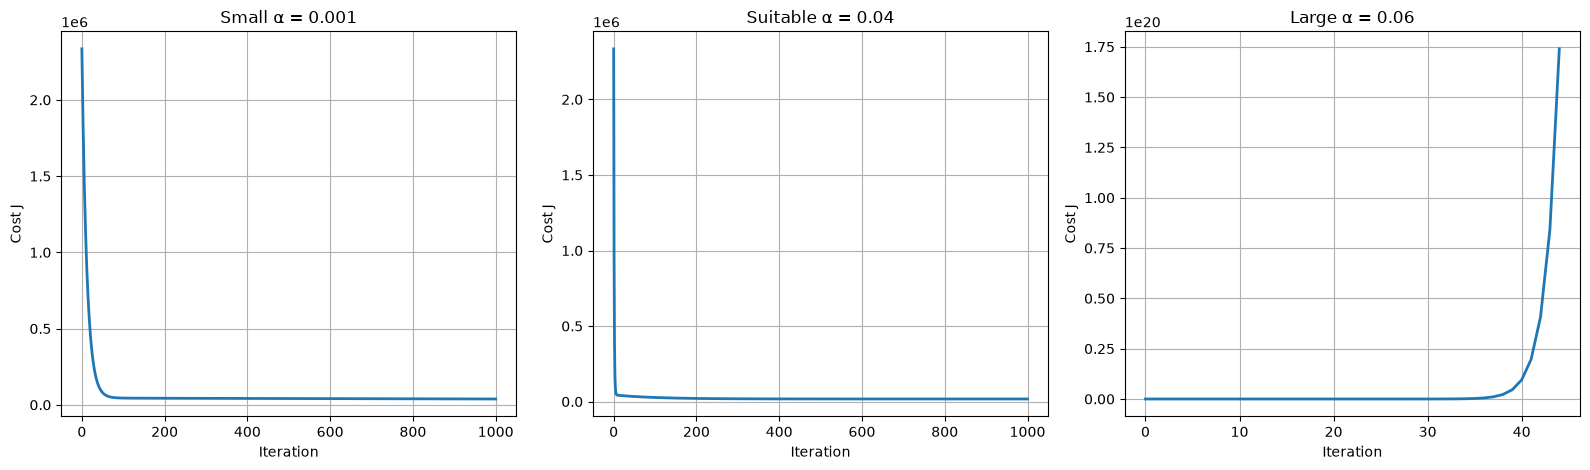


Final costs
Small α = 0.001: 38343.02
Suitable α = 0.04: 17234.60
Large α = 0.06: 173969462889732866048.00


In [28]:
learning_rates = {
    "Small α = 0.001": 0.001,
    "Suitable α = 0.04": 0.04,
    "Large α = 0.06": 0.06,
}

learning_rate_results = {}

for label, alpha_value in learning_rates.items():
    learning_rate_results[label] = gradient_descent(
        x=x,
        y=y,
        theta0_init=0.0,
        theta1_init=0.0,
        learning_rate=alpha_value,
        iterations=1000,
    )

fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 4.8),
)

for ax, (label, lr_result) in zip(
    axes,
    learning_rate_results.items(),
):
    costs = lr_result["cost_history"]

    ax.plot(
        costs,
        linewidth=2,
    )

    ax.set_title(label)
    ax.set_xlabel("Iteration")
    ax.set_ylabel("Cost J")
    ax.grid(True)

plt.tight_layout()
plt.show()

print("\nFinal costs")
for label, lr_result in learning_rate_results.items():
    print(
        f"{label}: "
        f"{lr_result['cost_history'][-1]:.2f}"
    )

In [ ]:
# ==================================================
# TRY YOUR OWN LEARNING RATE
# ==================================================
my_learning_rate = 0.02
my_iterations = 500
# ==================================================

my_result = gradient_descent(
    x=x,
    y=y,
    theta0_init=0.0,
    theta1_init=0.0,
    learning_rate=my_learning_rate,
    iterations=my_iterations,
)

fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(
    my_result["cost_history"],
    linewidth=2,
)

ax.set_xlabel("Iteration")
ax.set_ylabel("Cost J")
ax.set_title(
    f"My experiment: α = {my_learning_rate}"
)
ax.grid(True)

plt.show()

<div style="border-left:5px solid #b00020; padding:10px 14px; margin:14px 0;">
<div style="color:#b00020; font-weight:700;">Question</div>
<div style="margin-top:6px;"><b>Compare the three learning-rate plots. What happens when α is too small, suitable, and too large?</b></div>

<div style="color:#b00020; margin-top:8px;">
<b>Your answer:</b><br><br>
<br><br>
Problem with small cost function - 
<ul>
    <li> Wastes of resources - take more iteration to reach optimum value.</li>
    <li> If learning rate is small and cost is also small . Update become so small that it the progress kind of stuck.</li>
</ul>

Problem with too large cost function - 
<ul>
    <li> Value spikes up and down miss optimum value.</li>
</ul>
    ................................................................................................................................................
</div>

</div>

# 7. Use the Learned Model

The gradient descent model was trained with the GPU score divided by 10.

We can rewrite the learned equation using the original GPU score:

$$
h(\text{GPU score})
=
\theta_0
+
\frac{\theta_1}{10}(\text{GPU score})
$$

Change `new_gpu_score` and see the predicted laptop price.

In [ ]:
final_result = learning_rate_results[
    "Suitable α = 0.04"
]

theta0_final = final_result["theta0"]
theta1_final_scaled = final_result["theta1"]

theta1_final_gpu_score = theta1_final_scaled / 10.0

print("Learned model:")
print(
    f"price = {theta0_final:.3f} "
    f"+ ({theta1_final_gpu_score:.3f}) × GPU_score"
)

# ==================================================
# PLAY WITH THIS VALUE
# ==================================================
new_gpu_score = 70
# ==================================================

predicted_price = (
    theta0_final
    + theta1_final_gpu_score * new_gpu_score
)

print(
    f"\nPredicted laptop price for GPU score "
    f"{new_gpu_score}: "
    f"€{predicted_price:.2f}"
)

<div style="border-left:5px solid #b00020; padding:10px 14px; margin:14px 0;">
<div style="color:#b00020; font-weight:700;">Question</div>
<div style="margin-top:6px;"><b>Using the learned equation, explain how the prediction for a new laptop is calculated from θ₀, θ₁, and the GPU score.</b></div>

<div style="color:#b00020; margin-top:8px;">
<b>Your answer:</b><br><br>
New laptop price is being calculated with the formula y = θ₀+ θ * x here , x is the input gpu score and y is the predicted laptop price<br><br>
................................................................................................................................................
</div>

</div>

# Before You Finish

Make sure you can explain these ideas without looking at the code:

- what the gradient represents,
- what the learning rate does,
- what happens when the learning rate is too small,
- what happens when the learning rate is too large,
- why this is batch gradient descent,
- what the cost function measures,
- how to predict a laptop price using learned parameters.